# V05: OCI service hostname coverage

Record which of your selected OCI service endpoints can be configured and accessed through the workspace.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## Advanced DNS objective and coverage limits

**Why run it:** Verify selected service endpoints and distinguish endpoints that work through platform defaults from endpoints that need customer configuration. This complements the individual connectivity scenarios by examining coverage across actual resources.

**Current scope:** The notebook evaluates supplied configuration and authenticated-operation records for selected endpoints. Its checker does not determine whether an entry was automatically included. Configuration acceptance, a successful DNS lookup, or an authenticated read alone cannot prove automatic inclusion or removal of a support dependency.

**Additional manual acceptance for default resolution:**

1. Select an actual eligible endpoint using the documentation and capabilities of your deployed service. Record its region, endpoint type and supported operation. Do not treat a list of service families as an eligibility guarantee.
2. Capture the complete original customer DNS/SCAN configuration and establish whether a historical support override exists. Use a clean, approved test workspace if that history cannot be established; do not remove an override on a shared workspace to manufacture a baseline.
3. Before adding any entry, run runtime DNS and an authenticated read/query. Preserve evidence that the target is eligible and that no manual entry or historical override supplied its connectivity. Automatic platform behavior need not appear as an editable UI row.
4. Separately test any endpoint requiring explicit configuration. Label that result **manual configuration**, rather than automatic inclusion. Preserve the original policies and routes.
5. Review eligibility, configuration history, DNS, operation and path evidence together. If history or eligibility is unavailable, report automatic inclusion as **INCOMPLETE**, even if endpoint coverage succeeds. Identify whether a regional service-zone allowance, explicit mapping or default private DNS proxy supplied the observed behavior.

Classify regional service-zone allowances, explicit FQDN mappings and default private DNS proxy resolution separately. A private ADB name using the default proxy does not need an explicit entry solely because it is private. Cross-region public endpoints, S3 and customer source-context requirements can require explicit configuration. Success without a user entry does not by itself establish which mechanism supplied connectivity. Testing one resource does not establish coverage of all resources in its DNS zone. Keep the extra observations in a private companion record; the existing checker remains a selected-endpoint coverage check.


## DNS resolution path

Advanced DNS explicit entries and default private DNS proxy resolution serve different purposes. Determine the hostname's resolution path before editing the workspace.

| Mechanism | Resolution and traffic behavior | What to configure or verify |
| --- | --- | --- |
| Explicit Advanced DNS entry | Provisioning resolves the supplied public hostname from the service environment and installs an explicit mapping. The runtime DNS answer directs application traffic through the workspace private connection into the customer VCN. | Use a service-resolvable hostname requiring customer-network routing, then verify provisioning, saved state, workload DNS and the authenticated operation. A customer-VM lookup alone does not establish service-side resolvability. |
| Default private DNS proxy path | A private ADB hostname that the service resolver cannot resolve is handled through the private-endpoint DNS proxy and customer DNS context. | Verify customer DNS, private routes, listener security and the private descriptor. Do not add the private hostname solely because it is private. |
| Regional service-zone allowance | A regional service-domain policy permits covered zones in the applicable context. | Verify the deployment's eligibility and endpoint. This is neither an automatically inserted workspace entry nor proof that the private DNS proxy supplied the answer. |

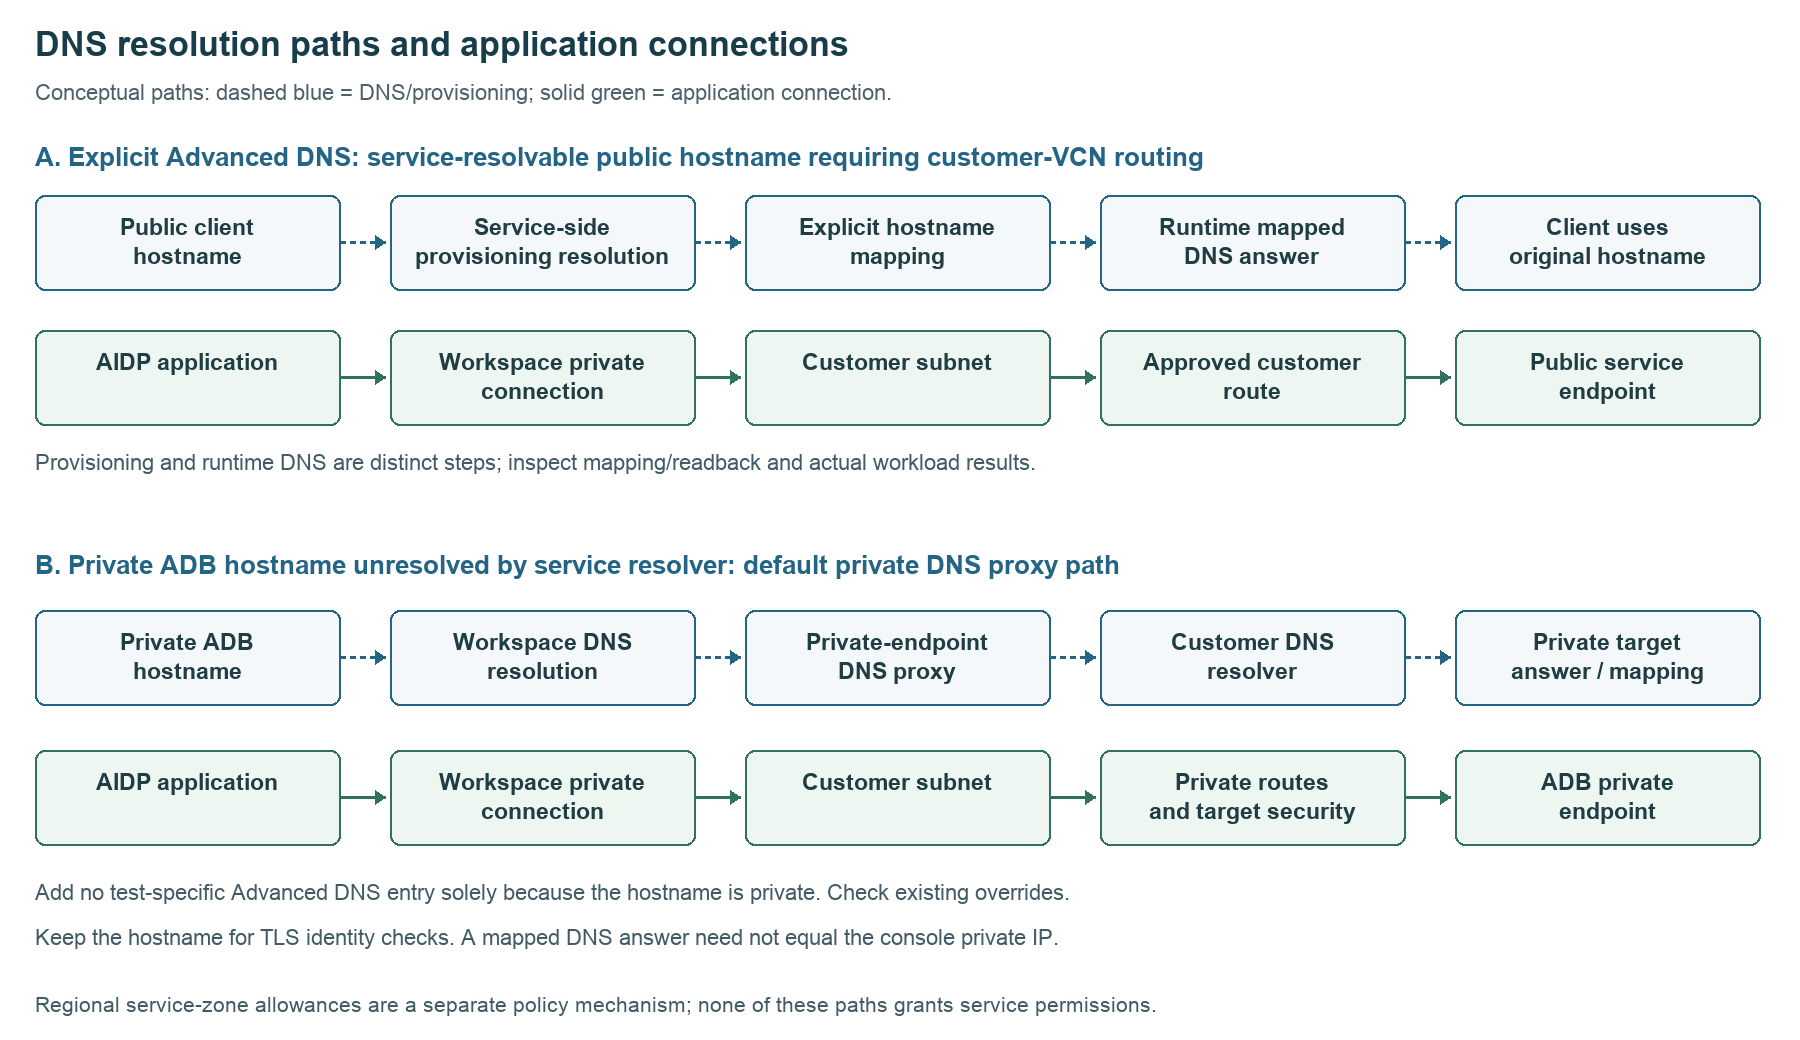

Dashed blue arrows describe DNS/provisioning relationships; solid green arrows show application connections. The diagram is conceptual, not a packet trace. An address returned inside AIDP can be a service-managed mapping and need not equal the private address in the destination console. Keep using the original hostname for TLS server identity checks.

**Before testing:** record the complete DNS/SCAN list, endpoint type, existing overrides and effective client configuration. A successful query alone does not identify the resolution mechanism. Do not delete a shared override to create a clean baseline. Use an approved clean test workspace or mark the default-path claim **INCOMPLETE** when provenance cannot be established.

For V04, first test the private endpoint without adding a test-specific Advanced DNS entry. For V01–V03, V06 and V07, explicit-entry tests require service-resolvable hostnames; private-only names are unsuitable for demonstrating that provisioning mechanism. An unresolved owned name can remain a deliberately negative V06 test.

The [public workspace guide](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html) lists broad private-network scenarios; endpoint type and deployed resolver behavior determine whether an explicit entry is necessary. The [ADB private endpoint guide](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html) describes the destination's private access setup. Confirm your deployment's behavior with the administrator and retain independent evidence for the resolution path you claim.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Inventory | Select actual resources you own. Possible coverage includes Autonomous Database, Streaming, OpenSearch, PostgreSQL, Data Flow interactive endpoints and Kafka endpoints. This is a test inventory, not a guarantee of automatic DNS insertion or a service-wide exception policy. |
| Route per service | Use each resource's real connection descriptor. Verify whether it needs an in-region service gateway, customer egress or a private route. Do not assume all selected services share a gateway or listener port. |
| DNS | Use actual resource FQDNs rather than probing only a service-zone root. Classify explicit mappings, regional service-zone allowances and default private DNS proxy behavior separately. Record saved configuration, override provenance and runtime results. |
| Security and service operation | Verify each service's firewall/NSG and authorization prerequisites and use a small supported read/query operation. Record unavailable fixtures as blocked coverage, not success. |
| Change control | Use owned test endpoints and restore only entries introduced for this coverage run. Record any additional support/configuration action required rather than assuming none. |


### Example network topology

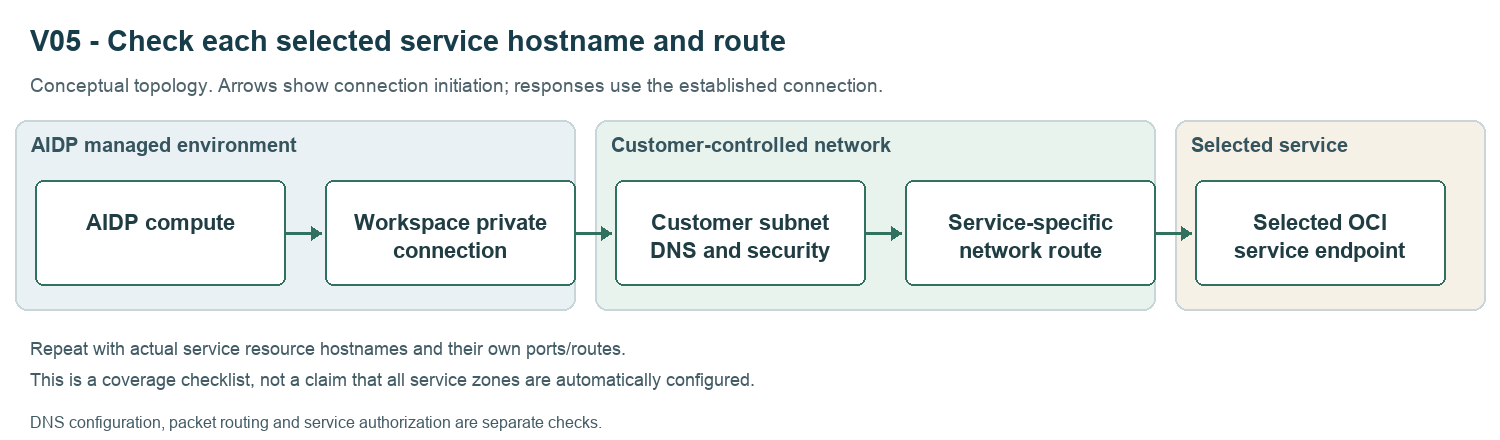

The diagram is illustrative; it does not prove the route taken by a request.


## IAM and network examples

Preparation templates only: replace every angle-bracket placeholder privately. An administrator prepares the approved resources; this notebook applies no policies or network changes.

### Separate operator, service and runtime permissions

The workspace operator needs access to the existing AIDP instance and the appropriate Workbench role/permissions to edit that workspace. Example OCI policies for an identity-domain group are:

```text
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to use ai-data-platforms in compartment <AIDP_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect vcns in compartment <VCN_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect subnets in compartment <SUBNET_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect network-security-groups in compartment <NSG_COMPARTMENT>
```

These statements allow instance access and network selection; they do not grant Workbench workspace-edit privileges, create infrastructure or authorize reads from data sources. Use the existing approved Workbench role. Policies belong in the relevant compartment or an ancestor with authority over that scope.

The platform also needs its private-network service permissions. The following adapts the documented AIDP network statements to explicit resource compartments and one instance:

```text
Allow any-user to manage vnics in compartment <VNIC_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use subnets in compartment <SUBNET_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use network-security-groups in compartment <NSG_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
```

Select the actual instance principal type (`aidataplatform` or the applicable legacy type), instance ID and placement compartments with your administrator. Retain the other existing service setup policies; this is not a full tenancy bootstrap. The runtime reading data can use a different identity from the operator or AIDP service: establish the connector's effective signer before choosing its policy subject.

Sources: [AIDP IAM policies](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/iam-policies-oracle-ai-data-platform.html), [AIDP workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html), [IAM policy scope](https://docs.oracle.com/en-us/iaas/Content/Security/Reference/iam_security_topic-IAM_Security_Policies.htm).

### Platform network baseline

The current workspace guide requires ingress from the customer VCN address range to all destination ports for private-network data access. An example baseline rule is **ingress; source CIDR `<CUSTOMER_VCN_CIDR>`; all protocols/ports; stateful**, in the security control selected for that workspace topology. Have the administrator reconcile this platform prerequisite with the approved design. The target-specific examples below are additional destination controls, not a replacement for platform rules. Do not use an internet-wide ingress rule.

Retain working DNS resolver access. With custom resolvers, permit UDP and TCP 53 to the approved resolver and configure forwarding/resolution in the customer network. Explicit Advanced DNS provisioning requires service-side resolvability; a successful customer-only lookup does not establish that prerequisite. Private ADB names unresolved by the service resolver use the default private DNS proxy/customer resolver path. Do not add them solely because they are private. Advanced DNS does not create a customer DNS zone, resolver endpoint, route, NAT gateway, service gateway or database listener. Use stateful connection rules in these examples; stateless designs need explicit return rules. Security lists and NSGs are additive, so check all applicable rules.

Source: [OCI security rules](https://docs.oracle.com/en-us/iaas/Content/Network/Concepts/securityrules.htm).

Reuse each selected service's existing runtime identity and approved topology. There is no universal IAM policy, listener port or gateway for all six possible service families. For ADB, use the V04 database login and private-route pattern where applicable; for Object Storage, use the V02/V03 bucket-scoped read pattern with the correct endpoint type and source requirement.

For an OCI Streaming REST consume test, this is an example user-group policy scoped to the selected stream:

```text
Allow group <IDENTITY_DOMAIN>/<STREAM_READERS> to use stream-pull in compartment <STREAM_COMPARTMENT> where target.stream.id='<TEST_STREAM_ID>'
```

This is a REST consume example, not a complete Kafka client setup. Use the actual message endpoint, required HTTPS route, and the client's supported authentication. Kafka consumer-group operations can require additional service permissions. PostgreSQL, OpenSearch, Kafka and interactive compute endpoints each need their own service/data-plane credentials and actual listener rules; adding their hostname does not grant query or consume access.

For every endpoint, record the operation, effective identity, required policy/role, route and listener rule. Missing service-specific permissions/fixtures mean **BLOCKED** coverage. For default behavior, capture the baseline and existing overrides before adding any hostname. Distinguish regional service-zone permission, explicit mapping and private DNS proxy fallback; do not call a private-proxy result automatic entry insertion.

Source: [OCI policy templates for Streaming](https://docs.oracle.com/en-us/iaas/Content/Identity/policiescommon/commonpolicies.htm).

### Supporting pattern: V02

### Runtime policy with source restriction

For a connector authenticated as a user in the named group, a fixture read can use:

```text
Allow group <IDENTITY_DOMAIN>/<FIXTURE_READERS> to read objects in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
Allow group <IDENTITY_DOMAIN>/<FIXTURE_READERS> to read buckets in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
```

For a connector using a verified resource-principal dynamic group, use that subject instead, for example:

```text
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read objects in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read buckets in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
```

Choose the subject matching the actual signer; do not grant both variants by default. An existing dynamic group must match that resource; these samples do not define a generic AIDP matching rule. Reading objects includes listing objects in the named bucket. No object write privilege is needed. If the chosen connector separately resolves the namespace, verify its namespace-read permission under its existing setup.

Create the Network Source in the tenancy home region with a **VCN entry** containing `<CUSTOMER_VCN_ID>` and `<WORKSPACE_SUBNET_CIDR>`. This is the allowed source network, not the translated destination address from a DNS answer. Keep the restriction unchanged during the comparison. OCI policies are additive: another unconditional allow for the same operation can invalidate this test; review effective grants before claiming a source restriction was enforced. Do not apply this example to the tenancy's console sign-in restriction.

### Route and security example

| Control | Example |
| --- | --- |
| Service gateway | Enable the supported Object Storage service label for `<WORKSPACE_REGION>`. |
| Subnet route | Destination type **Service**, destination the regional Object Storage service CIDR label, target `<SERVICE_GATEWAY_ID>`. |
| Egress | Destination type **Service**, same regional service label, stateful TCP 443. Preserve platform baseline rules. |
| Advanced DNS | Exact in-region service FQDN selected for customer source context. |

The service gateway serves supported services in its own region. Keep the policy, route and signer fixed; correlate the successful read with the intended source/path. A database ACL is a separate control.

Sources: [Network Sources](https://docs.oracle.com/en-us/iaas/Content/Identity/Tasks/managingnetworksources.htm), [service gateways](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm), [Object Storage policy examples](https://docs.oracle.com/en/solutions/oci-object-storage-modernization/configure-tenancy.html).

### Supporting pattern: V03

### Runtime read policy

For an existing dynamic group matching the connector's signer, grant access to the remote fixture bucket:

```text
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read objects in compartment <REMOTE_DATA_COMPARTMENT> where target.bucket.name='<REMOTE_TEST_BUCKET>'
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read buckets in compartment <REMOTE_DATA_COMPARTMENT> where target.bucket.name='<REMOTE_TEST_BUCKET>'
```

If the signer is a user, use `group <IDENTITY_DOMAIN>/<FIXTURE_READERS>` as the subject instead. Grant equivalent access to the separate in-region control fixture if it is not already authorized. These examples assume one tenancy; cross-tenancy access needs its own endorsement/admission arrangement. IAM permission does not configure a regional endpoint or establish a route.

### Route and security example

| Control | Example |
| --- | --- |
| Region A customer subnet | Default route `0.0.0.0/0` to existing `<NAT_GATEWAY_ID>` or approved egress appliance. |
| Remote destination | Region B public Object Storage endpoint, stateful TCP 443 to its approved ranges through the firewall/NSG. |
| Regional service route | Region A service gateway remains the Region A route; it cannot supply the Region B path. |
| Client and DNS | Explicit Region B bucket endpoint and its exact Advanced DNS FQDN where required; use a fresh client to avoid a cached Region A endpoint. |

If the remote bucket requires a Network Source, its restriction must match the actual approved egress context. The V02 customer-VCN/service-gateway condition is not automatically applicable to this NAT path. Do not remove a restriction just to pass the test.

Sources: [Object Storage policy examples](https://docs.oracle.com/en/solutions/oci-object-storage-modernization/configure-tenancy.html), [NAT gateway](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/NATgateway.htm), [HDFS endpoint configuration](https://docs.oracle.com/en-us/iaas/Content/API/SDKDocs/hdfsconnector.htm).

### Supporting pattern: V04

### Authorization example

The notebook's database identity query uses the existing database login/catalog credentials. OCI `manage autonomous-databases` is a control-plane permission, not permission to query database data. Reuse the existing approved login. If an administrator has already created a dedicated test database user, the connection privilege example is:

```sql
GRANT CREATE SESSION TO <TEST_DB_USER>;
```

The sample query reads `SYS_CONTEXT('USERENV','INSTANCE_NAME') FROM dual`; it does not need grants on application tables or catalog-wide dictionary access. An additional application-table test would need its own object grant. Existing AIDP catalog access must also be granted through Workbench. Wallet access, secret retrieval and IAM database authentication, if selected, have separate prerequisites; this SQL example does not configure them. Preserve TLS/mTLS and server identity checks.

### Route, resolver and NSG examples

| Control | Example |
| --- | --- |
| Same customer VCN | Existing local private routing to the service private endpoint; no NAT or internet gateway for that path. |
| Other VCN | Route `<DATABASE_SUBNET_CIDR>` to the approved LPG/DRG attachment in the source route table, reciprocal route `<WORKSPACE_SUBNET_CIDR>` in the target, and required peering/DRG route distribution. Use non-overlapping CIDRs. |
| Workspace egress | Stateful TCP to destination `<DATABASE_PRIVATE_IP>/32`, destination port `<DB_LISTENER_PORT>`, source ports unrestricted. |
| Database NSG ingress | Stateful TCP from `<WORKSPACE_SUBNET_CIDR>` or verified source NSG, destination port `<DB_LISTENER_PORT>`, source ports unrestricted. Use the actual customer-side source range observed for this topology. |
| Listener | Copy the actual private descriptor's port; 1522 is an mTLS example, not proof of client-certificate use. |
| DNS | Verify default private-endpoint DNS proxy resolution into customer DNS, forwarding/listening when needed, and the actual private runtime target. Add no test-specific Advanced DNS entry for this baseline. Capture existing override provenance. |

The destination NSG rule supplements the platform network baseline. Cross-VCN NSG references have scope limits: use the approved CIDR alternative where NSG-to-NSG referencing is unavailable. Default private DNS resolution does not create peering. Do not submit an unresolvable private-only hostname to the explicit mapping mechanism to repair a resolver/route problem.

Sources: [ADB user connection privileges](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/manage-users-create.html), [ADB private endpoint configuration](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html), [ADB connection modes](https://docs.oracle.com/en-us/iaas/autonomous-database-serverless/doc/connect-introduction.html).


## Test procedure

1. Fill required_services and one actual endpoint record for each selected service.
2. Capture baseline and override provenance per host; classify default private proxy, service-zone permission and explicit mapping separately. Record accepted/rejected operations only where an explicit entry is required.
3. Perform each service's existing authenticated operation and reference its evidence.
4. Evaluate the recorded coverage, review endpoint scope, and restore the baseline.

**Acceptance:** Each selected endpoint has configuration and authenticated-operation evidence. Do not generalize an endpoint result to an entire DNS zone or all service instances.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V05': 'OCI service hostname coverage'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def evaluate_evidence(case, evidence):
    """Validate explicitly supplied Workbench snapshots; never modify Workbench.

    These assertions check recorded observations. External source-path, private
    endpoint and mTLS claims always require human evidence review.
    """
    result = {'case': case, 'utc': utc(), 'origin': 'supplied evidence', 'checks': {}}
    checks = result['checks']
    if not evidence.get('evidence_ref'):
        checks['evidence'] = {'status': 'BLOCKED', 'reason': 'Missing evidence artifact reference'}
        return result

    def test(name, condition):
        checks[name] = {'status': 'PASS' if condition else 'FAIL'}
    before = evidence.get('before')
    restored = evidence.get('restored')
    services = evidence.get('services', [])
    required = evidence.get('required_services', [])
    if not required or not services:
        checks['service_inventory'] = {'status': 'BLOCKED', 'reason': 'Select services and their actual resource hostnames'}
        return result
    for service in required:
        matches = [s for s in services if s.get('service') == service]
        test(service, len(matches) == 1 and bool(matches[0].get('hostname')) and (matches[0].get('configuration_accepted') is True) and (matches[0].get('functional') == 'PASS') and bool(matches[0].get('saved_config_ref')) and bool(matches[0].get('operation_evidence_ref')))
    checks['coverage_review'] = {'status': 'REVIEW_REQUIRED', 'reason': 'Review endpoint scope and observed configuration; no automatic service-wide claim'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V05'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


### Service observation format

Select your own required_services labels. Add one service record per selected resource using this shape. A missing fixture is blocked coverage. Accepted DNS configuration is not an authenticated read.


In [ ]:
SERVICE_RECORD_EXAMPLE = {"service": "", "hostname": "", "configuration_accepted": None, "saved_config_ref": None, "functional": None, "operation_evidence_ref": None, "additional_configuration_notes": ""}


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None, 'required_services': [], 'services': []}


In [ ]:
if RUN_EVIDENCE_CHECKS:
    observed = evaluate_evidence(CASE_ID, EVIDENCE)
    observed["acceptance"] = summarize(observed)
    RESULTS.append(observed)
    print(json.dumps(observed, indent=2))
else:
    print("Evidence assertions NOT_RUN; capture real observations first.")


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)
- [sgw](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
